# Задание 1. Инициализация весов и функции активации

Берем `BaseNetwork` из условия: полносвязная сеть $784 \to 512 \to 256 \to 256 \to 128 \to 10$, после каждого скрытого слоя стоит одна и та же функция активации. Сначала посмотрим, как от инициализации весов зависят активации и градиенты в разных слоях сразу после инициализации, а потом - как это сказывается на обучении обычным SGD на FashionMNIST.

Функции активации: ReLU, tanh, identity (тогда сеть - просто произведение матриц, глубокая линейная модель) и для бонусного пункта еще sigmoid и GELU.

In [1]:
import math
import sys
import time
import unittest

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display

from utils import BaseNetwork, set_seed, load_fashion_mnist, train_epoch, evaluate

## 1.1. Данные

Данные грузим общей функцией `load_fashion_mnist()`: картинки уже нормированы (среднее 0 и std 1 по всей обучающей выборке) и вытянуты в векторы длины 784.

In [2]:
x_train, y_train, x_test, y_test = load_fashion_mnist()
print("train:", tuple(x_train.shape), " test:", tuple(x_test.shape))
print(f"среднее пикселя {x_train.mean():.3f}, std {x_train.std():.3f}")

train: (60000, 784)  test: (10000, 784)
среднее пикселя 0.000, std 1.000


## 1.2. Функции активации

Кроме трех обязательных взял sigmoid (классическая насыщающаяся функция, к тому же не центрированная - ее выход в среднем около 0.5) и GELU (гладкий вариант ReLU, который используют в трансформерах). Для дальнейшего полезно помнить производные в нуле: у identity и tanh $f'(0)=1$, у sigmoid $f'(0)=1/4$, а ReLU пропускает градиент только там, где вход положительный, т.е. примерно для половины нейронов.

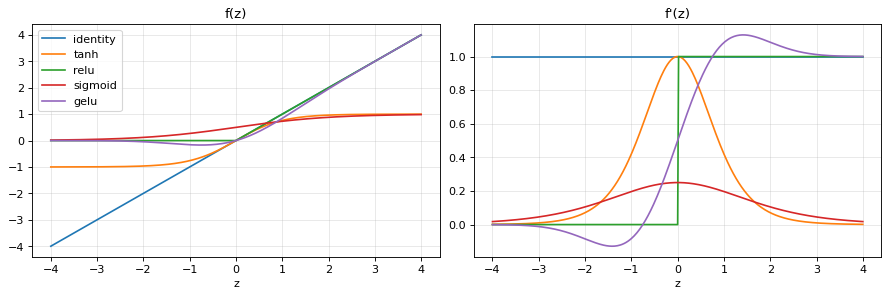

In [3]:
ACT_FNS = {
    "identity": nn.Identity,
    "tanh": nn.Tanh,
    "relu": nn.ReLU,
    "sigmoid": nn.Sigmoid,  # бонус
    "gelu": nn.GELU,        # бонус
}

def plot_activation_functions():
    z = torch.linspace(-4, 4, 401, requires_grad=True)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), dpi=80, layout="constrained")
    for name, act_cls in ACT_FNS.items():
        f_z = act_cls()(z)
        (df_z,) = torch.autograd.grad(f_z.sum(), z)
        axes[0].plot(z.detach(), f_z.detach(), label=name)
        axes[1].plot(z.detach(), df_z, label=name)
    axes[0].set_title("f(z)")
    axes[1].set_title("f'(z)")
    for ax in axes:
        ax.set_xlabel("z")
        ax.grid(alpha=0.3)
    axes[0].legend()
    plt.show()


plot_activation_functions()

## 1.3. Инициализации

Немного теории. Пусть $y = Wx$, веса $W_{ij}$ независимы, $\mathbb{E}W_{ij}=0$, $\mathrm{Var}\,W_{ij}=\sigma^2$, и не зависят от входа $x$, у которого нулевое среднее. Тогда

$$\mathrm{Var}\,y_i = \sum_{j=1}^{n_{in}} \mathrm{Var}(W_{ij} x_j) = n_{in}\,\sigma^2\,\mathrm{Var}\,x_j .$$

Чтобы дисперсия сигнала не менялась от слоя к слою, нужно $\sigma^2 = 1/n_{in}$ (инициализация LeCun). На обратном проходе $\frac{\partial L}{\partial x_j} = \sum_i W_{ij}\frac{\partial L}{\partial y_i}$, и точно так же получается $\mathrm{Var}\,\frac{\partial L}{\partial x} = n_{out}\,\sigma^2\, \mathrm{Var}\,\frac{\partial L}{\partial y}$, т.е. для градиентов нужно $\sigma^2 = 1/n_{out}$. Если $n_{in} \ne n_{out}$, оба условия сразу не выполнить, поэтому Glorot и Bengio берут компромисс

$$\sigma^2_{Xavier} = \frac{2}{n_{in} + n_{out}}.$$

Вывод сделан для линейной сети, так что он подходит для identity и для tanh (около нуля $\tanh z \approx z$). Так как tanh все-таки сжимает сигнал, в PyTorch для него std еще домножают на gain $=5/3$.

У ReLU половина входов зануляется: если $z$ распределено симметрично, то $\mathbb{E}[\mathrm{ReLU}(z)^2] = \frac12 \mathrm{Var}\,z$. Значит $\mathrm{Var}\,z^{(l)} = \frac12\, n_{in}\, \sigma^2\, \mathrm{Var}\,z^{(l-1)}$, и чтобы дисперсия сохранялась, He et al. берут

$$\sigma^2_{He} = \frac{2}{n_{in}}.$$

Что сравниваем (смещения везде нулевые):
- `const` - все веса равны 0.005. Все нейроны слоя получают одинаковые входы и одинаковые градиенты, так что симметрия между ними никогда не ломается.
- `normal_0.01`, `normal_0.1`, `normal_1` - $\mathcal N(0, \sigma^2)$ с фиксированным std, который не зависит от размера слоя. Для первого слоя ($n_{in}=784$) множитель $\sqrt{n_{in}}\,\sigma$ равен 0.28, 2.8 и 28, так что для 0.01 ждем затухания сигнала, а для 0.1 и 1 - роста или насыщения.
- `xavier` - $\mathcal N\big(0,\ g^2 \cdot \frac{2}{n_{in}+n_{out}}\big)$, где $g = 5/3$ для tanh и $g=1$ для остальных (для ReLU и GELU это обычный Glorot, чтобы было видно, что дает поправка He).
- `kaiming` - $\mathcal N\big(0,\ g^2 / n_{in}\big)$, gain под активацию: $g=\sqrt2$ для ReLU и GELU, $5/3$ для tanh, $1$ для identity и sigmoid (для них это инициализация LeCun). То же самое, что `nn.init.kaiming_normal_(w, nonlinearity=...)`.

Для sigmoid все сложнее. Около нуля $\sigma(z) \approx \frac12 + \frac z4$, поэтому иногда для нее берут Xavier с gain 4: это компенсирует множитель $\sigma'(0)=1/4$ для той части сигнала, которая меняется от картинки к картинке. Но постоянное смещение 0.5 никакой масштаб весов не убирает. В основном сравнении у sigmoid gain 1 (как в PyTorch, `calculate_gain("sigmoid") = 1`), а вариант с gain 4 отдельно проверим в конце п. 1.5.

Инициализацию пишу сам: std считаю по fan_in/fan_out и заполняю веса через `normal_` / `fill_` под `torch.no_grad()`.

In [4]:
INIT_METHODS = ["const", "normal_0.01", "normal_0.1", "normal_1", "xavier", "kaiming"]
CONST_INIT_VALUE = 0.005
ACT_GAINS = {"identity": 1.0, "sigmoid": 1.0, "tanh": 5 / 3, "relu": math.sqrt(2), "gelu": math.sqrt(2)}


def init_std(method, fan_in, fan_out, act_name, gain=None):
    # std нормального распределения для весов слоя fan_in -> fan_out (gain можно задать вручную)
    if method.startswith("normal_"):
        return float(method.split("_", 1)[1])
    if method == "xavier":
        if gain is None:
            gain = ACT_GAINS["tanh"] if act_name == "tanh" else 1.0
        return gain * math.sqrt(2.0 / (fan_in + fan_out))
    if method == "kaiming":
        if gain is None:
            gain = ACT_GAINS[act_name]
        return gain / math.sqrt(fan_in)
    raise ValueError(f"неизвестная инициализация: {method}")


@torch.no_grad()
def init_weights_(model, method, act_name, gain=None):
    # инициализирует на месте все nn.Linear в model: веса по схеме method, смещения нулями
    # act_name обязателен: от него зависит gain у xavier и kaiming
    for layer in model.modules():
        if not isinstance(layer, nn.Linear):
            continue
        fan_out, fan_in = layer.weight.shape
        if method == "const":
            layer.weight.fill_(CONST_INIT_VALUE)
        else:
            layer.weight.normal_(0.0, init_std(method, fan_in, fan_out, act_name, gain))
        if layer.bias is not None:
            layer.bias.zero_()
    return model


def make_init_model(act_name, method, seed=0, gain=None):
    # BaseNetwork с нужной активацией и инициализацией
    set_seed(seed)
    model = BaseNetwork(ACT_FNS[act_name]())
    return init_weights_(model, method, act_name, gain)


LAYER_FANS = [(l.in_features, l.out_features) for l in BaseNetwork(nn.ReLU()).layers if isinstance(l, nn.Linear)]
LAYER_LABELS = [f"слой {i + 1}: {fi}->{fo}" for i, (fi, fo) in enumerate(LAYER_FANS)]

# std весов по слоям для разных схем
init_std_table = pd.DataFrame(
    {f"{m} ({a})": [init_std(m, fi, fo, a) for fi, fo in LAYER_FANS]
     for m, a in [("xavier", "identity"), ("xavier", "tanh"), ("kaiming", "identity"), ("kaiming", "relu")]},
    index=LAYER_LABELS,
)
display(init_std_table.round(4))

,xavier (identity),xavier (tanh),kaiming (identity),kaiming (relu)
слой 1: 784->512,0.0393,0.0655,0.0357,0.0505
слой 2: 512->256,0.0510,0.0851,0.0442,0.0625
слой 3: 256->256,0.0625,0.1042,0.0625,0.0884
слой 4: 256->128,0.0722,0.1203,0.0625,0.0884
слой 5: 128->10,0.1204,0.2006,0.0884,0.1250


Проверим реализацию тестами: с тем же сидом наши `kaiming` и `xavier` (в том числе с вручную заданным gain) должны совпадать с `nn.init`, эмпирический std на большой матрице - с формулой, смещения должны быть нулевыми, а `const` - давать одинаковые веса.

In [5]:
class TestWeightInit(unittest.TestCase):
    def test_kaiming_matches_nn_init(self):
        for act_name, nonlinearity in [("relu", "relu"), ("tanh", "tanh"), ("identity", "linear")]:
            ours, ref = nn.Linear(300, 200), nn.Linear(300, 200)
            torch.manual_seed(1)
            init_weights_(ours, "kaiming", act_name)
            torch.manual_seed(1)
            nn.init.kaiming_normal_(ref.weight, nonlinearity=nonlinearity)
            torch.testing.assert_close(ours.weight.data, ref.weight.data)

    def test_xavier_matches_nn_init(self):
        cases = [("tanh", None, nn.init.calculate_gain("tanh")), ("relu", None, 1.0),
                 ("sigmoid", None, 1.0), ("sigmoid", 4.0, 4.0)]  # последний - gain задан вручную
        for act_name, our_gain, ref_gain in cases:
            ours, ref = nn.Linear(300, 200), nn.Linear(300, 200)
            torch.manual_seed(2)
            init_weights_(ours, "xavier", act_name, gain=our_gain)
            torch.manual_seed(2)
            nn.init.xavier_normal_(ref.weight, gain=ref_gain)
            torch.testing.assert_close(ours.weight.data, ref.weight.data)

    def test_empirical_std_and_zero_bias(self):
        layer = nn.Linear(1000, 500)
        torch.manual_seed(3)
        for method, act_name in [("normal_0.1", "relu"), ("xavier", "tanh"), ("kaiming", "relu")]:
            init_weights_(layer, method, act_name)
            expected = init_std(method, 1000, 500, act_name)
            self.assertAlmostEqual(layer.weight.std().item() / expected, 1.0, delta=0.01)
            self.assertEqual(layer.bias.abs().max().item(), 0.0)

    def test_const(self):
        model = make_init_model("relu", "const")
        for layer in model.layers:
            if isinstance(layer, nn.Linear):
                self.assertTrue(torch.all(layer.weight == CONST_INIT_VALUE))


init_suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestWeightInit)
unittest.TextTestRunner(verbosity=2, stream=sys.stdout).run(init_suite);

test_const (__main__.TestWeightInit.test_const) ... 

ok


test_empirical_std_and_zero_bias (__main__.TestWeightInit.test_empirical_std_and_zero_bias) ... 

ok


test_kaiming_matches_nn_init (__main__.TestWeightInit.test_kaiming_matches_nn_init) ... 

ok


test_xavier_matches_nn_init (__main__.TestWeightInit.test_xavier_matches_nn_init) ... 

ok


----------------------------------------------------------------------
Ran 4 tests in 0.172s

OK


## 1.4. Активации и градиенты сразу после инициализации

Берем фиксированный батч из 1024 случайных картинок обучающей выборки. Прямой проход делаю вручную по `model.layers` и запоминаю выход после каждой активации (4 скрытых слоя) и логиты. Хуки на `act_fn` вешать неудобно: в `BaseNetwork` один и тот же объект активации стоит во всех слоях, и непонятно, какой вызов к какому слою относится. Потом один backward кросс-энтропии и смотрим на градиенты двух видов: градиент лосса по выходу каждого слоя $\partial L / \partial h_l$ (для этого на выходах вызываю `retain_grad()`) и градиенты весов каждого `nn.Linear`, которые как раз и использует SGD. Сами тензоры не храню - только std, среднее и гистограммы.

In [6]:
def tensor_summary(t, bins=60):
    # std, среднее, RMS и гистограмма по центральным 99% значений
    v = t.detach().flatten().double()
    v_min, v_max = v.min().item(), v.max().item()
    lo, hi = torch.quantile(v, torch.tensor([0.005, 0.995], dtype=v.dtype)).tolist()
    if not hi > lo:
        lo, hi = lo - 1e-12, hi + 1e-12
    counts, edges = np.histogram(v.numpy(), bins=bins, range=(lo, hi))
    return {"std": v.std().item(), "mean": v.mean().item(), "rms": v.pow(2).mean().sqrt().item(),
            "n": v.numel(), "counts": counts, "edges": edges,
            # все значения одинаковые (с точностью до округления) - гистограмма вырождается в одну точку
            "single_value": v_max - v_min <= 1e-6 * max(abs(v_min), abs(v_max))}


def collect_layer_stats(model, xb, yb):
    # выходы слоев (после активации, последний - логиты), градиенты лосса по ним
    # и градиенты весов всех nn.Linear после одного backward
    model.zero_grad()
    outs, h = [], xb
    last = len(model.layers) - 1
    for i, layer in enumerate(model.layers):
        h = layer(h)
        if not isinstance(layer, nn.Linear) or i == last:
            h.retain_grad()
            outs.append(h)
    loss = nn.functional.cross_entropy(h, yb)
    loss.backward()
    act_stats = []
    for a in outs:
        s = tensor_summary(a)
        s["neuron_std"] = a.detach().std(dim=1).mean().item()  # разброс между нейронами на одном примере
        s["sample_std"] = a.detach().std(dim=0).mean().item()  # разброс выхода нейрона по разным картинкам
        act_stats.append(s)
    out_grad_stats = [tensor_summary(a.grad) for a in outs]
    grad_stats = [tensor_summary(l.weight.grad) for l in model.layers if isinstance(l, nn.Linear)]
    return {"loss": loss.item(), "acts": act_stats, "out_grads": out_grad_stats, "grads": grad_stats}


def collect_all_init_stats(xb, yb):
    # статистики сразу после инициализации для всех пар (активация, инициализация)
    stats = {}
    for act_name in ACT_FNS:
        for method in INIT_METHODS:
            stats[(act_name, method)] = collect_layer_stats(make_init_model(act_name, method, seed=0), xb, yb)
    return stats


set_seed(0)
probe_idx = torch.randperm(len(x_train))[:1024]
x_probe, y_probe = x_train[probe_idx], y_train[probe_idx]

init_stats = collect_all_init_stats(x_probe, y_probe)
print("посчитано комбинаций:", len(init_stats))

посчитано комбинаций: 30


Сначала сводный график в зависимости от номера слоя (слой 5 - логиты):
- верхний ряд - std выходов слоев (пунктир - уровень 1);
- средний ряд - RMS градиента лосса по выходу слоя $\partial L / \partial h_l$. Лосс усреднен по батчу из 1024 картинок, поэтому сами числа маленькие (порядка $10^{-4}$ на логитах), важно, как они меняются от слоя к слою;
- нижний ряд - RMS градиентов весов (корень из среднего квадрата; при нулевом среднем это то же, что std, но он не обнуляется, если все градиенты одинаковые).

По одной панели на активацию и по линии на инициализацию, шкала логарифмическая. У `const` градиенты всех скрытых слоев фактически нулевые ($10^{-9}$ и меньше, точные числа - в таблице ниже, столбцы "rms dL/dh1" и "rms grad W1"). Если рисовать их честно, ось растянется на много порядков вниз, поэтому на градиентных рядах эти точки прижаты к нижнему краю панели (серые треугольники), а нормальная точка у `const` только одна - последний слой. Стабильной будем называть инициализацию, при которой линия идет примерно горизонтально, без роста или падения на порядки.

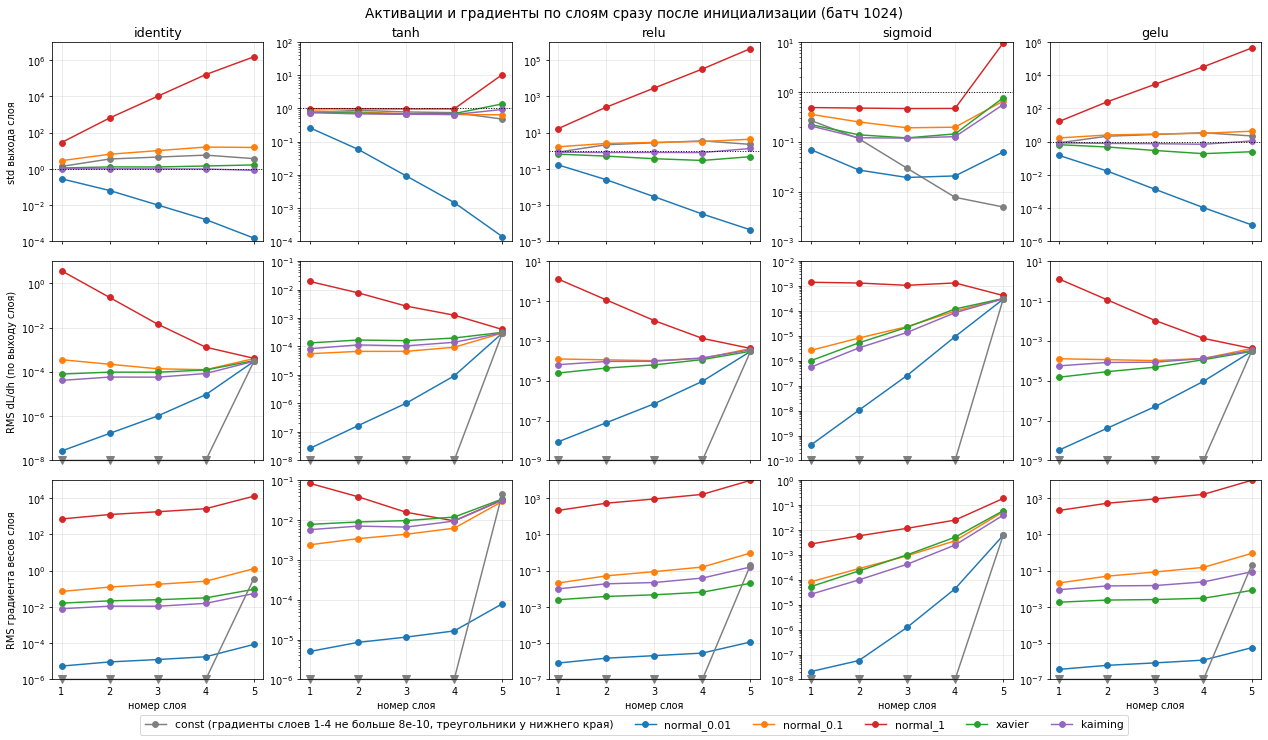

In [7]:
INIT_COLORS = dict(zip(INIT_METHODS, ["tab:gray", "tab:blue", "tab:orange", "tab:red", "tab:green", "tab:purple"]))


def snap_log_ylim(ax, values):
    # границы логарифмической оси по целым порядкам, чтобы подписи были хотя бы на двух уровнях
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v) & (v > 0)]
    ax.set_ylim(10.0 ** np.floor(np.log10(v.min())), 10.0 ** np.ceil(np.log10(v.max())))


def plot_const_grads(ax, layer_idx, vals):
    # у const градиенты скрытых слоев ~0: такие точки ставим на нижний край оси треугольниками
    vals = np.asarray(vals, dtype=float)
    y_low = ax.get_ylim()[0]
    below = vals < y_low
    color = INIT_COLORS["const"]
    ax.plot(layer_idx, np.maximum(vals, y_low), "-", color=color, clip_on=False)
    ax.plot(layer_idx[~below], vals[~below], "o", color=color)
    ax.plot(layer_idx[below], np.full(below.sum(), y_low), "v", ms=9, color=color, clip_on=False)
    return vals[:-1].max()


def plot_init_summary():
    layer_idx = np.arange(1, len(LAYER_FANS) + 1)
    panel_rows = [("acts", "std", "std выхода слоя"),
                  ("out_grads", "rms", "RMS dL/dh (по выходу слоя)"),
                  ("grads", "rms", "RMS градиента весов слоя")]
    fig, axes = plt.subplots(3, len(ACT_FNS), figsize=(18, 10.5), dpi=70, sharex=True, layout="constrained")
    const_hidden_max = 0.0
    for c, act_name in enumerate(ACT_FNS):
        for r, (kind, key, ylabel) in enumerate(panel_rows):
            ax, plotted = axes[r, c], []
            for method in INIT_METHODS:
                vals = [s[key] for s in init_stats[(act_name, method)][kind]]
                if kind != "acts" and method == "const":
                    plotted.append(vals[-1])  # скрытые слои рисуем отдельно, когда известна ось
                    continue
                ax.plot(layer_idx, vals, "o-", color=INIT_COLORS[method], label=method)
                plotted += vals
            ax.set_yscale("log")
            snap_log_ylim(ax, plotted)
            if kind != "acts":
                const_vals = [s[key] for s in init_stats[(act_name, "const")][kind]]
                const_hidden_max = max(const_hidden_max, plot_const_grads(ax, layer_idx, const_vals))
            ax.grid(alpha=0.3)
            if c == 0:
                ax.set_ylabel(ylabel)
        axes[0, c].set_title(act_name, fontsize=13)
        axes[0, c].axhline(1.0, color="black", ls=":", lw=1)
        axes[-1, c].set_xlabel("номер слоя")
        axes[-1, c].set_xticks(layer_idx)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    labels[INIT_METHODS.index("const")] = f"const (градиенты слоев 1-4 не больше {const_hidden_max:.0e}, треугольники у нижнего края)"
    fig.legend(handles, labels, loc="outside lower center", ncol=len(INIT_METHODS), fontsize=11)
    fig.suptitle("Активации и градиенты по слоям сразу после инициализации (батч 1024)", fontsize=14)
    plt.show()


plot_init_summary()

Те же числа таблицей: std выхода последнего скрытого слоя (слой 4) и его среднее, "std по нейронам" (std по нейронам слоя 4 на одном примере, усредненный по батчу; если он 0, все нейроны слоя одинаковые), "std по примерам" (std выхода одного нейрона по разным картинкам, усредненный по нейронам; если он маленький, слой почти не зависит от входа), std логитов, RMS градиента по выходу первого слоя и его отношение к градиенту по логитам, RMS градиента весов первого и последнего слоя и их отношение (насколько градиент затухает к началу сети).

In [8]:
def make_init_table(stats):
    table_rows = []
    for (act_name, method), st in stats.items():
        a, dh, g = st["acts"], st["out_grads"], st["grads"]
        table_rows.append({
            "активация": act_name,
            "инициализация": method,
            "loss": st["loss"],
            "std слой 4": a[-2]["std"],
            "mean слой 4": a[-2]["mean"],
            "std по нейронам": a[-2]["neuron_std"],
            "std по примерам": a[-2]["sample_std"],
            "std логитов": a[-1]["std"],
            "rms dL/dh1": dh[0]["rms"],
            "dh1 / dh5": dh[0]["rms"] / dh[-1]["rms"],
            "rms grad W1": g[0]["rms"],
            "rms grad W5": g[-1]["rms"],
            "W1 / W5": g[0]["rms"] / g[-1]["rms"],
        })
    return pd.DataFrame(table_rows).set_index(["активация", "инициализация"])


init_table = make_init_table(init_stats)
with pd.option_context("display.float_format", "{:.3g}".format, "display.width", 250, "display.max_columns", 20):
    display(init_table)

loss  std слой 4  mean слой 4  std по нейронам  std по примерам  std логитов  rms dL/dh1  dh1 / dh5  rms grad W1  rms grad W5  W1 / W5
активация инициализация                                                                                                                                           
identity  const              2.3        5.76        0.112                0             5.76         3.69    4.28e-13   1.46e-09     2.34e-10         0.37 6.31e-10
          normal_0.01        2.3      0.0016    -6.16e-05          0.00157           0.0013     0.000153    2.66e-08   9.07e-05     5.46e-06     8.55e-05   0.0639
          normal_0.1        20.9          16       -0.616             15.7               13         15.3    0.000352      0.894       0.0713         1.28   0.0555
          normal_1      2.08e+06     1.6e+05    -6.16e+03         1.57e+05          1.3e+05     1.53e+06        3.64   8.93e+03          713     1.29e+04   0.0553
          xavier            3.15        1.45      -0.0557             1.42             1.17         1.66     7.9e-05      0.248       0.0162       0.0935    0.173
          kaiming           2.51       0.987       -0.038            0.968            0.799        0.831     4.1e-05      0.137      0.00799       0.0547    0.146
tanh      const              2.3       0.751      -0.0428                0            0.751         0.48    1.01e-13   3.44e-10     2.25e-11       0.0455 4.94e-10
          normal_0.01        2.3     0.00148    -6.42e-05          0.00145          0.00119      0.00014    2.65e-08   9.04e-05     5.04e-06     7.88e-05   0.0639
          normal_0.1        2.39       0.657      -0.0359            0.658            0.583        0.646    5.58e-05      0.188      0.00238        0.029    0.082
          normal_1          15.6       0.973      -0.0328            0.974            0.936         10.5      0.0191       48.2       0.0827       0.0319     2.59
          xavier            2.84       0.703      -0.0396            0.704            0.616         1.37    0.000133      0.426      0.00773       0.0334    0.231
          kaiming           2.51       0.658      -0.0378            0.659            0.571        0.933    8.37e-05      0.278       0.0057       0.0312    0.183
relu      const              2.3        3.53         2.48                0             3.53         2.26    3.01e-13   1.03e-09     1.58e-10        0.206 7.67e-10
          normal_0.01        2.3    0.000324      0.00021         0.000315         0.000164     4.34e-05    8.58e-09   2.93e-05     8.02e-07     1.16e-05    0.069
          normal_0.1        9.58        3.24          2.1             3.15             1.64         4.34    0.000123      0.301       0.0208         0.94   0.0222
          normal_1      9.54e+05    3.24e+04      2.1e+04         3.15e+04         1.64e+04     4.34e+05        1.25   3.01e+03          211     9.65e+03   0.0219
          xavier            2.41       0.293         0.19            0.285            0.148        0.473    2.42e-05     0.0811       0.0025       0.0202    0.124
          kaiming            3.4       0.799        0.517            0.778            0.404         1.34    6.34e-05      0.182      0.00992         0.16   0.0622
sigmoid   const              2.3     0.00767        0.717                0          0.00767      0.00491    3.15e-15   1.07e-11     2.79e-13        0.006 4.65e-11
          normal_0.01       2.31      0.0206          0.5           0.0207         4.92e-06       0.0624    4.13e-10   1.41e-06     2.07e-08      0.00605 3.42e-06
          normal_0.1        2.59       0.196        0.492            0.196            0.015        0.653     2.6e-06    0.00842      8.3e-05       0.0532  0.00156
          normal_1          23.3       0.465        0.454            0.467            0.189         9.53     0.00141        3.4      0.00271        0.182   0.0149
          xavier            2.68       0.144        0.498            0.144          0.00295        0.759       1e-06

Теперь подробнее - гистограммы. Для каждой функции активации две картинки: распределение выходов слоев и распределение градиентов весов. Строки - инициализации, столбцы - слои, в заголовке std (для градиентов RMS). Масштаб по оси x у каждой гистограммы свой (по центральным 99% значений), поэтому важно смотреть на заголовок и на подписи оси. Если в гистограмме есть узкий пик (например, нули после ReLU), он обрезан сверху, а его доля подписана в углу. Если же все значения в подграфике одинаковые (так бывает с градиентами скрытых слоев при `const`), вместо гистограммы из одного столбика написано само значение.

In [9]:
def plot_layer_hists(act_name, kind):
    what = {"acts": "выходы слоев", "grads": "градиенты весов"}[kind]
    color = "tab:blue" if kind == "acts" else "tab:red"
    fig, axes = plt.subplots(len(INIT_METHODS), len(LAYER_FANS), figsize=(15, 11.5), dpi=72, layout="constrained")
    for r, method in enumerate(INIT_METHODS):
        for c, s in enumerate(init_stats[(act_name, method)][kind]):
            ax = axes[r, c]
            title = f"std={s['std']:.2g}" if kind == "acts" else f"rms={s['rms']:.2g}"
            ax.set_title(LAYER_LABELS[c] + "\n" + title if r == 0 else title, fontsize=10)
            ax.set_yticks([])
            if s["single_value"]:
                # гистограмма из одного столбика ничего не показывает, пишем само значение
                ax.text(0.5, 0.5, f"все значения\nравны {s['mean']:.3g}", transform=ax.transAxes,
                        ha="center", va="center", fontsize=10)
                ax.set_xticks([])
                continue
            ax.stairs(s["counts"], s["edges"], fill=True, color=color, alpha=0.75)
            second = np.sort(s["counts"])[-2]
            if second > 0 and s["counts"].max() > 4 * second:
                # узкий пик (например, нули после ReLU) обрезаем, чтобы было видно остальное
                ax.set_ylim(0, 1.3 * second)
                share = s["counts"].max() / s["n"]
                ax.text(0.97, 0.95, f"пик {share:.0%}", transform=ax.transAxes, ha="right", va="top", fontsize=9)
            ax.xaxis.set_major_locator(plt.MaxNLocator(3))
            ax.ticklabel_format(axis="x", useOffset=False)
            ax.tick_params(axis="x", labelsize=9)
            if c == 0:
                ax.set_ylabel(method, fontsize=11)
    fig.suptitle(f"{act_name}: {what} (строки - инициализации, столбцы - слои)", fontsize=14)
    plt.show()

### Identity

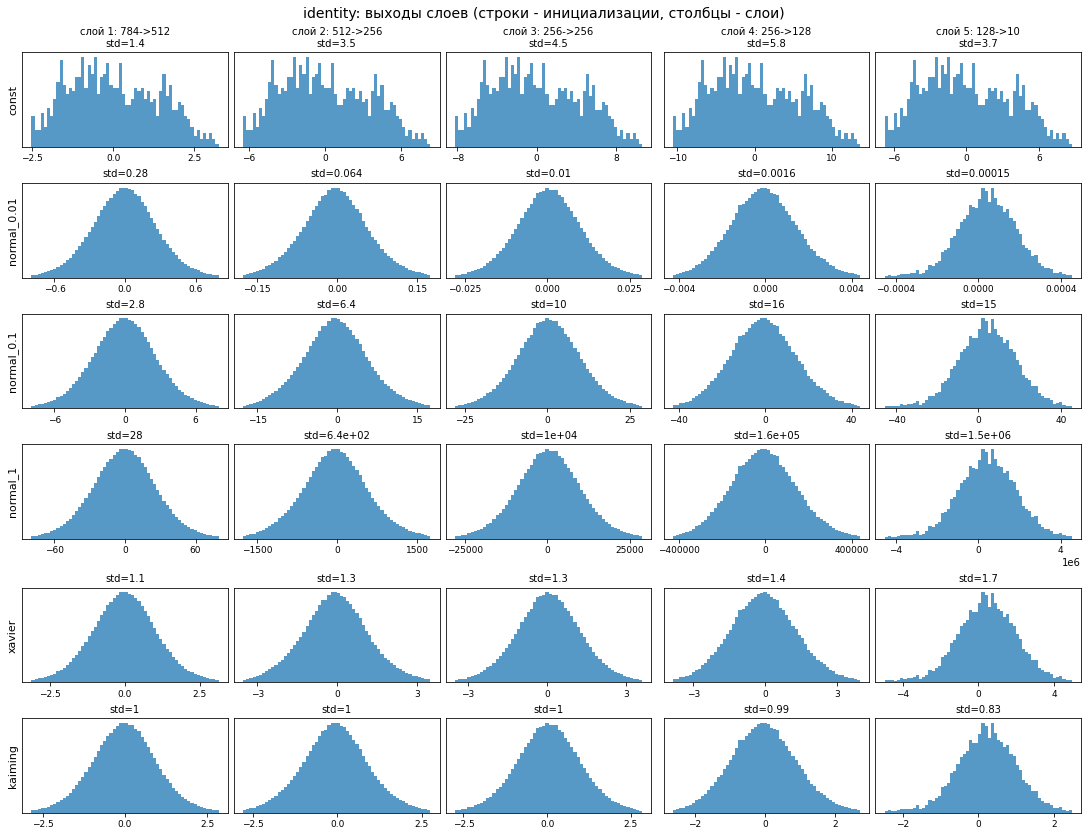

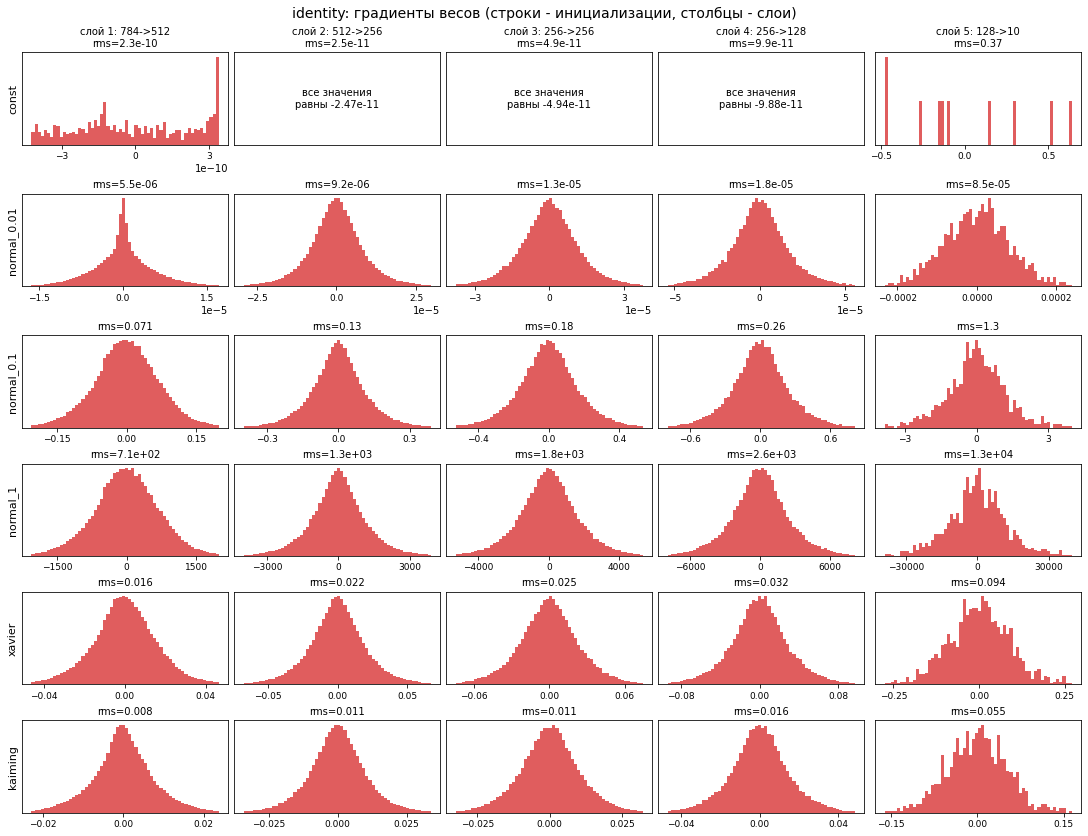

In [10]:
plot_layer_hists("identity", "acts")
plot_layer_hists("identity", "grads")

Для identity сеть линейная, поэтому выходы всех слоев распределены нормально и отличаются только масштабом. Каждый слой умножает std примерно на $\sqrt{n_{in}}\,\sigma$: при `normal_0.01` это 0.28, 0.23, 0.16, 0.16, 0.11, и к логитам std падает до 1.5e-4, а при `normal_0.1` и `normal_1` сигнал наоборот растет (std логитов 15 и 1.5e6). `kaiming` (здесь это LeCun, $\sigma^2 = 1/n_{in}$) держит std около 1 во всех скрытых слоях (1.02, 1.02, 1.01, 0.99), `xavier` дает небольшой рост от 1.1 до 1.45 в скрытых слоях (1.66 на логитах): у нас везде $n_{out} \le n_{in}$, поэтому $\frac{2}{n_{in}+n_{out}} \ge \frac{1}{n_{in}}$ (равенство только в слое 256->256, там Xavier совпадает с LeCun). Градиенты весов масштабируются так же: порядка 1e-5 при `normal_0.01`, 1e-2 при `xavier` и `kaiming`, 1e3-1e4 при `normal_1`.

У `const` std выхода ненулевой, но это разброс между картинками, а не между нейронами (в таблице std по нейронам ровно 0). Градиенты скрытых слоев порядка 1e-10, т.е. фактически нулевые - почему, разберем в выводах ниже.

### Tanh

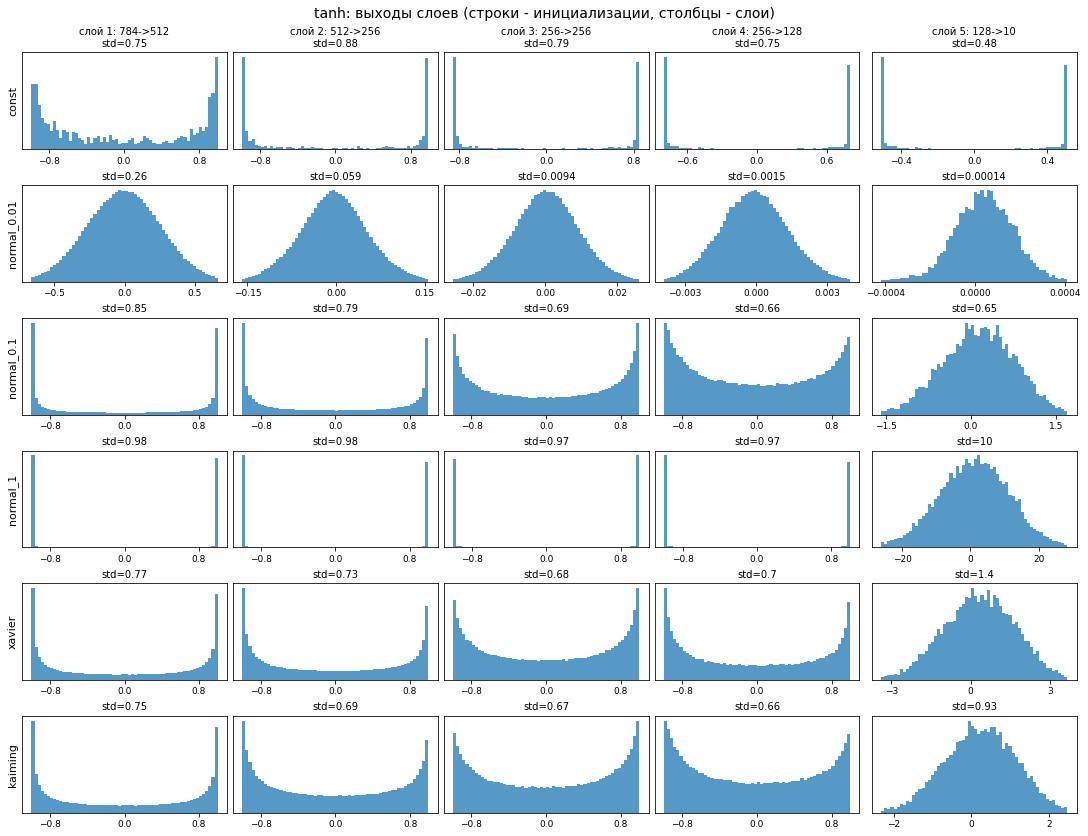

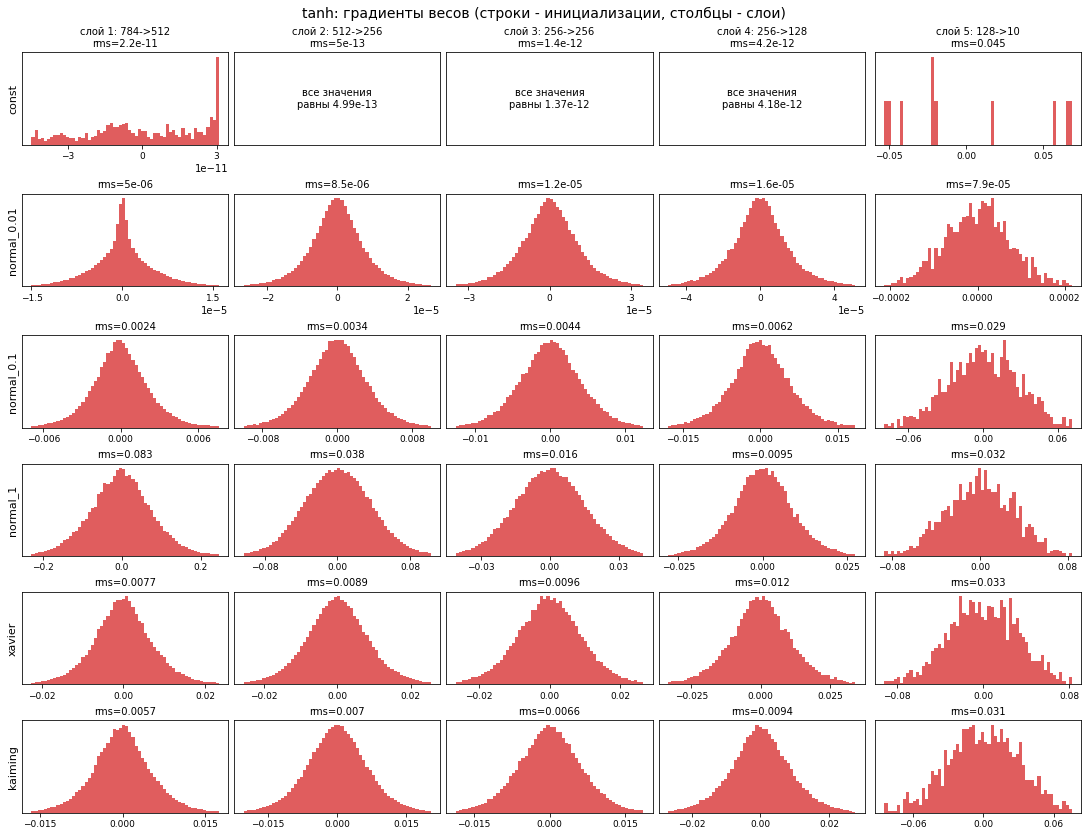

In [11]:
plot_layer_hists("tanh", "acts")
plot_layer_hists("tanh", "grads")

У tanh картина другая, потому что выход ограничен. При `normal_1` предактивации огромные и почти все нейроны в насыщении: на гистограммах два пика в $\pm 1$, std около 0.98. Сигнал не взрывается, но std логитов около 10, и начальный лосс 15.6 вместо $\ln 10 \approx 2.3$. При `normal_0.1` первый слой тоже сильно насыщен, но дальше насыщение слабее. При `normal_0.01` tanh работает в линейной области, и сигнал затухает так же, как в линейной сети (до 1.4e-4 на логитах). `xavier` (с gain 5/3) и `kaiming` дают одинаково ровную картину: std 0.66-0.77 во всех скрытых слоях, распределение U-образное (часть нейронов около насыщения, но не все), RMS градиента от первого слоя к последнему меняется в 4-6 раз, а не на порядки.

### ReLU

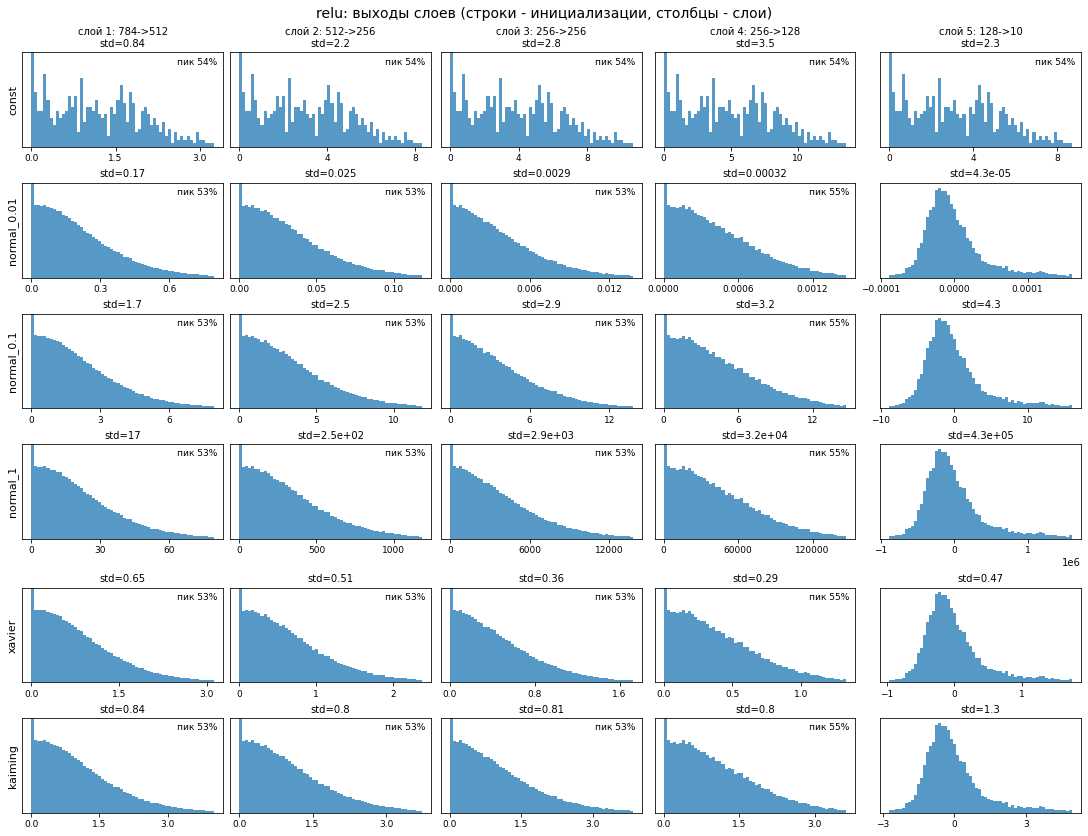

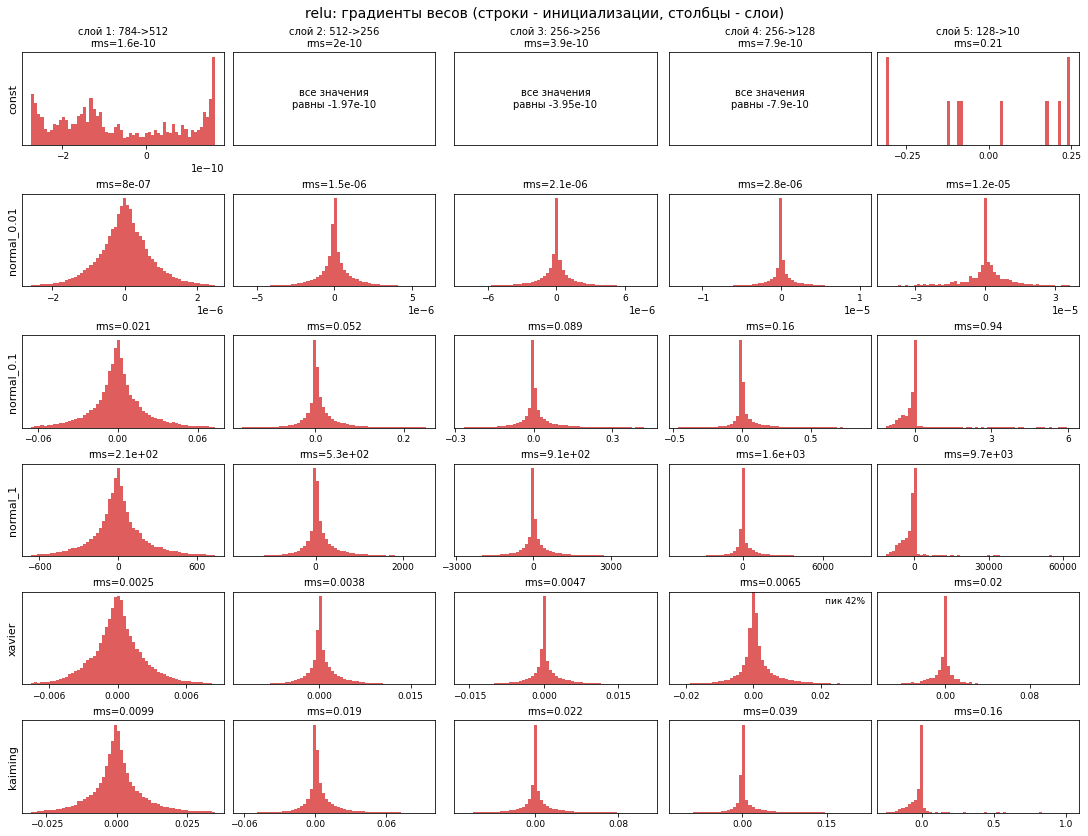

In [12]:
plot_layer_hists("relu", "acts")
plot_layer_hists("relu", "grads")

У ReLU примерно половина выходов - ровно ноль (пик около 50% на гистограммах), так что после каждого слоя второй момент сигнала уменьшается вдвое. `kaiming` это компенсирует: std скрытых слоев 0.84, 0.80, 0.81, 0.80. `xavier` без поправки теряет примерно четверть std на каждом слое (0.65, 0.51, 0.36, 0.29), ровно как предсказывает множитель $\sqrt{n_{in}/(n_{in}+n_{out})}$. На четырех слоях это еще не катастрофа, но в сети поглубже сигнал бы заметно затух. `normal_0.1` раздувает сигнал умеренно (3.2 в слое 4, 4.3 на логитах, начальный лосс 9.6), а `normal_1` дает настоящий взрыв: std растет в 11-15 раз на каждом слое, логиты порядка 4e5, RMS градиентов от 2e2 до 1e4. При `normal_0.01` все наоборот: и активации, и градиенты (1e-6 - 1e-5) почти нулевые.

### Sigmoid (бонус)

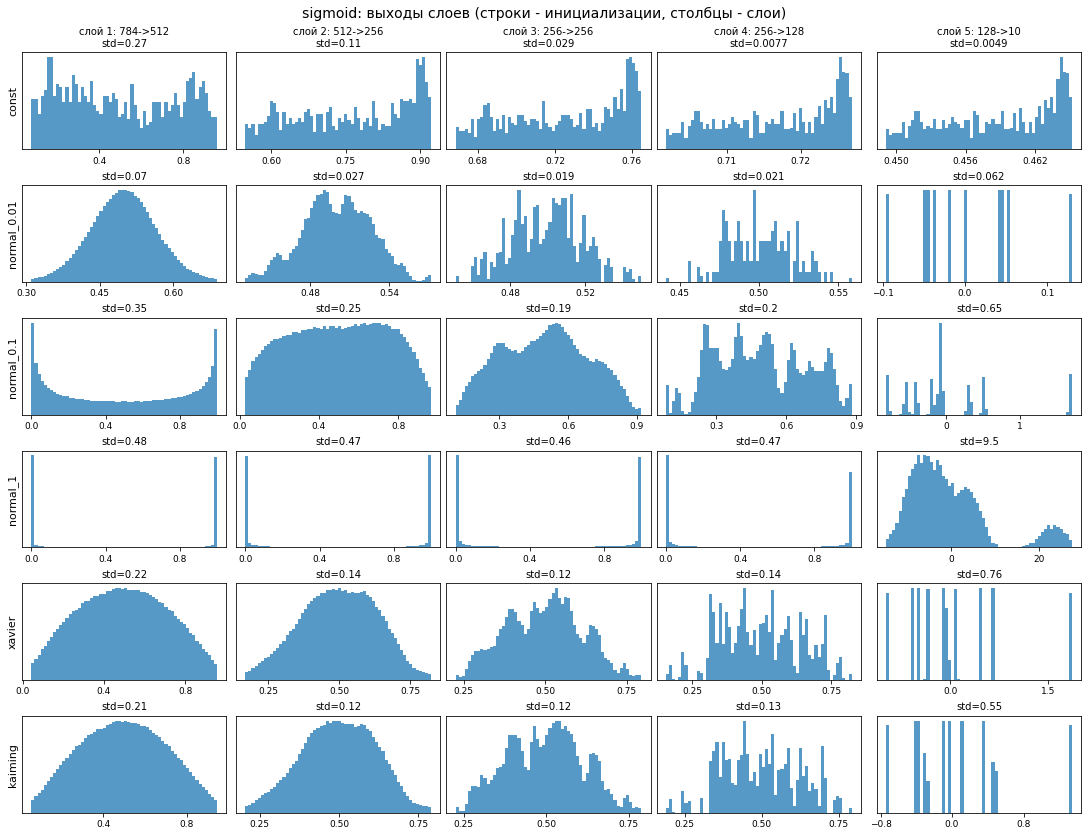

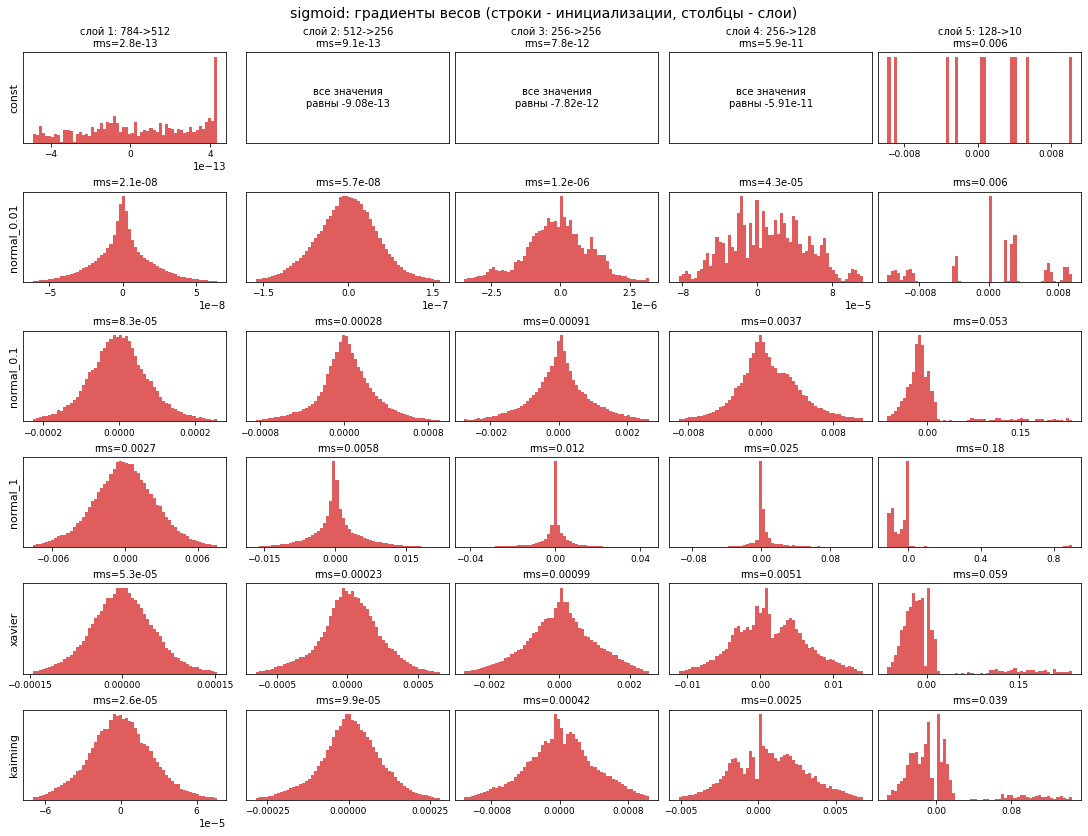

In [13]:
plot_layer_hists("sigmoid", "acts")
plot_layer_hists("sigmoid", "grads")

Sigmoid - самый неудачный случай. Ее выход всегда положительный и в среднем около 0.5 (в таблице mean слоя 4 почти ровно 0.5), поэтому следующий слой получает большую постоянную добавку $0.5 \sum_j W_{ij}$, одинаковую для всех картинок. А полезная часть сигнала (то, чем картинки отличаются друг от друга) на каждом слое умножается примерно на $\sigma'(0) = 1/4$: при `xavier` std по примерам падает 0.18, 0.047, 0.011, 0.003. В итоге общий std активаций выглядит прилично (0.12-0.22), но это в основном разброс между нейронами, а сама сеть почти не видит вход: логиты на гистограмме превращаются в набор узких пиков, по одному на класс, т.е. для всех картинок сеть выдает почти одно и то же.

Градиенты тоже затухают к началу сети. Градиент по выходу слоя при `xavier` уменьшается в 4-5 раз на каждом слое (1.2e-4 в слое 4, потом 2.2e-5, 5.2e-6 и 1e-6 в слое 1), как и должно быть при $\sigma' \le 1/4$. Для весов это дает RMS градиента первого слоя 5.3e-5 против 0.059 у последнего (примерно в 1000 раз меньше), при `kaiming` так же, при `normal_0.01` - в 300 000 раз. `normal_1` загоняет нейроны в насыщение (пики в 0 и 1), но большие веса частично компенсируют маленькую производную: полезный сигнал затухает медленнее всего (std по примерам 0.19 в слое 4), градиент по выходам скрытых слоев почти одинаковый (около 1.3e-3), а градиент весов первого слоя меньше, чем у последнего, "всего" в 70 раз. Среди шести основных вариантов хорошей инициализации для sigmoid нет, а Xavier с gain 4 проверим отдельно после основного обучения.

### GELU (бонус)

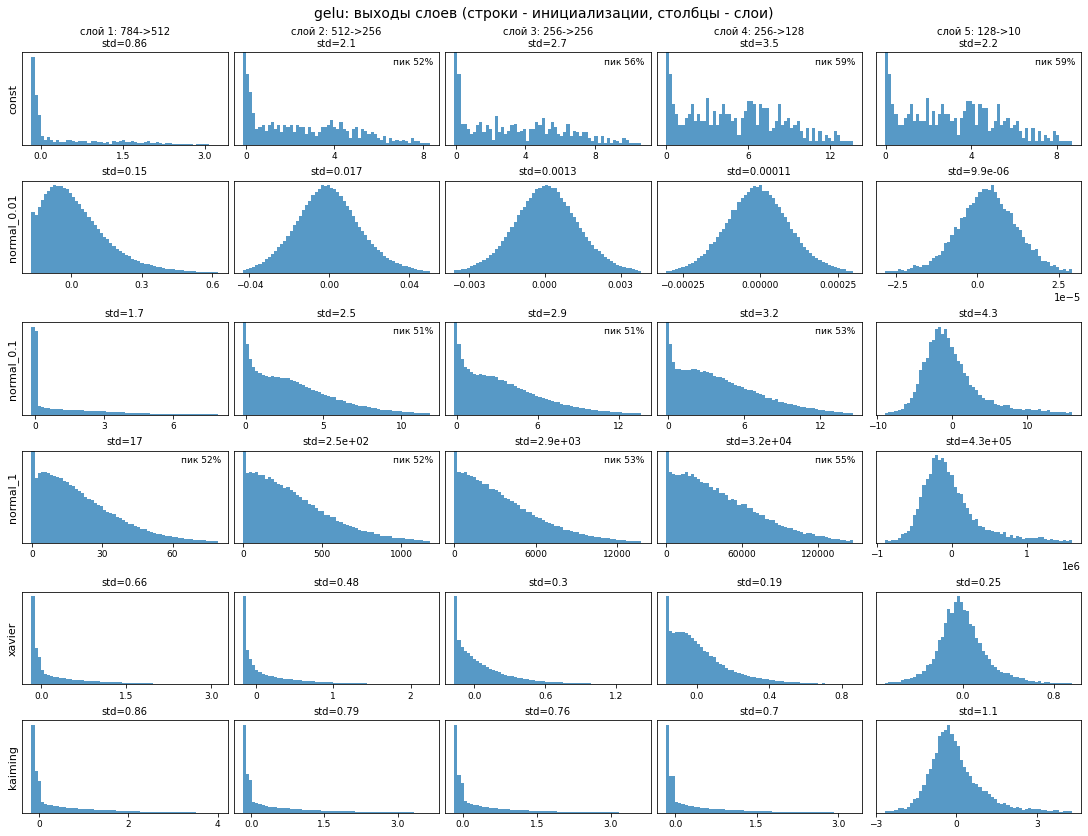

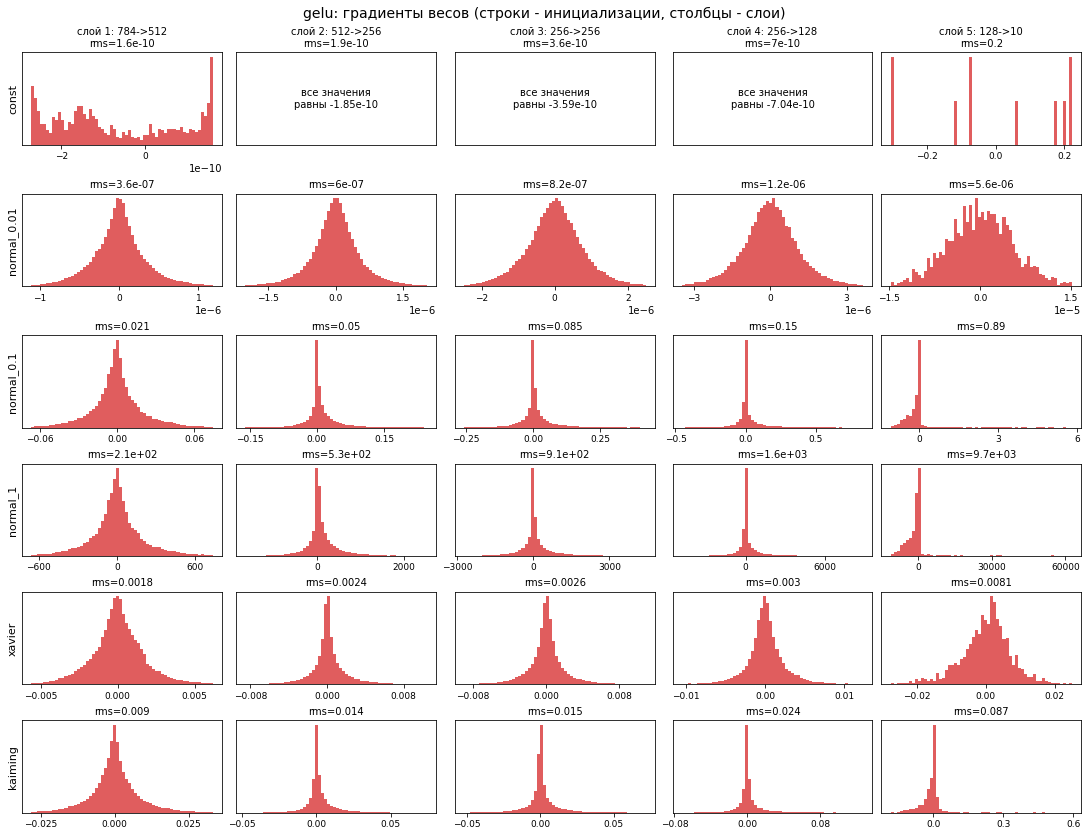

In [14]:
plot_layer_hists("gelu", "acts")
plot_layer_hists("gelu", "grads")

GELU похожа на ReLU: отрицательные предактивации почти зануляются (пик около нуля), поэтому и картина почти такая же. `kaiming` с gain $\sqrt2$ работает хорошо, но std слегка проседает с глубиной (0.86, 0.79, 0.76, 0.70): для $z \sim \mathcal N(0,1)$ у GELU $\mathbb{E}[\mathrm{GELU}(z)^2] \approx 0.42$, а не 0.5, как у ReLU, так что множителя $\sqrt2$ чуть-чуть не хватает. По той же причине `xavier` затухает быстрее, чем у ReLU (0.66, 0.48, 0.30, 0.19). При `normal_1` значения огромные, и GELU там совпадает с ReLU - цифры одинаковые до третьего знака.

### Выводы по инициализации

- `const`: все нейроны слоя одинаковые (std по нейронам ровно 0 для всех активаций). Более того, градиенты скрытых слоев на старте нулевые (не больше 1e-9 - это ошибки округления). Все веса последнего слоя равны одному числу $c$, поэтому $\frac{\partial L}{\partial h_j} = c \sum_k (p_k - y_k) = 0$, ведь вероятности софтмакса в сумме дают 1. Сначала учится только последний слой, а симметрия между нейронами не нарушится никогда (проверим после обучения).
- `normal_0.01`: сигнал затухает при любой активации, каждый слой умножает std на $\sqrt{n_{in}} \cdot 0.01 \approx 0.1-0.3$. Логиты (кроме sigmoid) порядка 1e-4 - 1e-5, т.е. на старте сеть выдает равномерное распределение (лосс 2.30 = $\ln 10$), градиенты 1e-4 и меньше.
- `normal_0.1`: умеренный рост для identity (логиты ~15) и ReLU/GELU (~4), для tanh все почти нормально (ограниченность спасает), для sigmoid - затухание полезного сигнала.
- `normal_1`: взрыв для identity, ReLU и GELU (логиты 1e5 - 1e6, градиенты до 1e4) и полное насыщение для tanh и sigmoid.
- Градиенты по выходам слоев $\partial L / \partial h_l$ (средний ряд сводного графика) ведут себя как сигнал на прямом проходе, только в обратную сторону: при `normal_0.01` они уменьшаются к началу сети в 6-10 раз на каждом слое (у ReLU от 9.3e-6 в слое 4 до 8.6e-9 в слое 1), при `normal_1` наоборот растут (у ReLU от 1.3e-3 до 1.25), а при хороших инициализациях почти не меняются по скрытым слоям (ReLU + `kaiming`: 6.3e-5, 9.2e-5, 9.4e-5, 1.4e-4).
- identity: стабильна `kaiming` (то есть LeCun, $1/n_{in}$), std около 1 во всех слоях. `xavier` близко, с небольшим ростом к выходу.
- tanh: стабильны `xavier` с gain 5/3 и `kaiming` (с тем же gain): std 0.66-0.77 во всех слоях, градиенты по слоям меняются в 4-6 раз.
- ReLU: стабильна `kaiming` ($2/n_{in}$), std около 0.8 во всех скрытых слоях. Обычный `xavier` теряет примерно по 25% std на слой.
- GELU: тоже лучше всего `kaiming`, хотя небольшое затухание (до 0.70 в слое 4) все же есть.
- Отношение RMS градиентов первого и последнего слоя даже у хороших вариантов меньше 1 (0.06-0.23), и это нормально: сеть сужается к выходу (512 -> 10), а при инициализации по $n_{in}$ на обратном проходе дисперсия на каждом слое умножается на $n_{out}/n_{in} \le 1$ (видно и по среднему ряду графика: самый большой скачок градиента по выходу - между логитами и слоем 4, где 10 выходов против 128 входов). Важно, что это разы, а не порядки, как у sigmoid.
- sigmoid: ни одна из шести схем не дает стабильного сигнала. Из-за смещенного среднего и $\sigma' \le 1/4$ полезная часть сигнала и градиенты затухают к началу сети: градиент по выходу слоя в 4-5 раз на слой, а градиент весов первого слоя в 1000 раз меньше, чем последнего, даже при `xavier` и `kaiming`.

## 1.5. Сходимость на FashionMNIST с SGD

Теперь обучаем каждую пару (активация, инициализация). Настройки для всех запусков одинаковые: `torch.optim.SGD` без momentum, lr = 0.02, батч 256, 6 эпох, сид 0. Из-за одного и того же сида порядок батчей везде одинаковый, а у `normal_0.01`, `normal_0.1` и `normal_1` веса - это одна и та же случайная матрица, просто умноженная на разные числа, так что сравнение получается честным. 6 эпох - чтобы все 30 запусков уложились в несколько минут на CPU; основные эффекты (скорость на старте, плато, расхождение) видны уже к 2-3 эпохе.

Почему lr = 0.02: в пробных запусках с lr = 0.05 линейная сеть (identity) с `xavier` расходилась уже на первой эпохе, а при 0.02 нормально учатся все "хорошие" инициализации. Подбирать lr под каждую инициализацию отдельно не стал - хочется видеть влияние именно инициализации.

Расхождение ловим так: после каждой эпохи проверяем, не было ли `nan`/`inf` в лоссе или в норме градиента. Если были, запуск помечается как разошедшийся, дальше не обучается, и запоминается номер итерации, где это случилось впервые. Остановиться посреди эпохи `train_epoch` из общих функций не умеет, так что эпоха, в которой все сломалось, досчитывается до конца с `nan` (это пара секунд на запуск). Для оценки на тесте используем `evaluate` оттуда же.

In [15]:
SGD_LR, SGD_BATCH, SGD_EPOCHS, SGD_SEED = 0.02, 256, 6, 0
ITERS_PER_EPOCH = math.ceil(len(x_train) / SGD_BATCH)


def train_with_init(act_name, method, epochs=SGD_EPOCHS, lr=SGD_LR, batch_size=SGD_BATCH, seed=SGD_SEED, gain=None):
    # обучение BaseNetwork с заданной инициализацией обычным SGD; возвращает модель и историю
    model = make_init_model(act_name, method, seed, gain)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    gen = torch.Generator().manual_seed(seed)
    hist = {"iter_loss": [], "iter_grad": [], "train_loss": [], "test_loss": [], "test_acc": [], "diverged_at": None}
    for epoch in range(1, epochs + 1):
        losses, grad_norms = train_epoch(model, x_train, y_train, optimizer, batch_size=batch_size, generator=gen)
        losses, grad_norms = np.array(losses), np.array(grad_norms)
        bad = ~(np.isfinite(losses) & np.isfinite(grad_norms))
        if bad.any():
            first_bad = int(np.argmax(bad))
            hist["iter_loss"] += losses[:first_bad].tolist()
            hist["iter_grad"] += grad_norms[:first_bad].tolist()
            # номер итерации (с начала обучения), на которой впервые получился nan/inf
            hist["diverged_at"] = (epoch, len(hist["iter_loss"]) + 1)
            break
        hist["iter_loss"] += losses.tolist()
        hist["iter_grad"] += grad_norms.tolist()
        hist["train_loss"].append(losses.mean())
        test_loss, test_acc = evaluate(model, x_test, y_test)
        hist["test_loss"].append(test_loss)
        hist["test_acc"].append(test_acc)
    # насколько различаются нейроны первого слоя: std по нейронам для каждого пикселя, берем максимум
    hist["w1_neuron_spread"] = model.layers[0].weight.detach().std(dim=0).max().item()
    return model, hist


def run_all_trainings():
    # обучает все пары (активация, инициализация), печатает итог по каждой
    hists, w1_weights = {}, {}
    t0 = time.time()
    for act_name in ACT_FNS:
        for method in INIT_METHODS:
            model, hist = train_with_init(act_name, method)
            hists[(act_name, method)] = hist
            if act_name == "relu" and method in ("const", "kaiming"):
                w1_weights[method] = model.layers[0].weight.detach().clone()
            if hist["diverged_at"] is not None:
                epoch, it = hist["diverged_at"]
                status = f"разошлось на эпохе {epoch}: nan/inf на итерации {it}"
                if hist["iter_loss"]:
                    status += ", до этого лосс " + ", ".join(f"{v:.2g}" for v in hist["iter_loss"][-3:])
            else:
                status = f"train loss {hist['train_loss'][-1]:.3f}, test acc {hist['test_acc'][-1]:.4f}"
            print(f"{act_name:>8} | {method:<11} | {status}")
    print(f"всего обучение заняло {(time.time() - t0) / 60:.1f} мин")
    return hists, w1_weights


train_hist, w1_examples = run_all_trainings()

identity | const       | train loss 1.813, test acc 0.2491


identity | normal_0.01 | train loss 1.840, test acc 0.2378


identity | normal_0.1  | разошлось на эпохе 1: nan/inf на итерации 9, до этого лосс 1e+03, 9.2e+04, 1.9e+12


identity | normal_1    | разошлось на эпохе 1: nan/inf на итерации 3, до этого лосс 2.1e+06, 3.1e+16


identity | xavier      | train loss 0.422, test acc 0.8354


identity | kaiming     | train loss 0.427, test acc 0.8366


... (20 outputs left out)

    gelu | normal_0.1  | train loss 0.331, test acc 0.8498


    gelu | normal_1    | разошлось на эпохе 1: nan/inf на итерации 3, до этого лосс 9.7e+05, 1.2e+16


    gelu | xavier      | train loss 0.345, test acc 0.8599


    gelu | kaiming     | train loss 0.314, test acc 0.8624
всего обучение заняло 9.1 мин


Кривые обучения: лосс на трейне по итерациям (скользящее среднее по 25 батчам, по оси x - эпохи), точность на тесте после каждой эпохи и норма градиента по всем параметрам (тоже сглаженная). Для лосса и нормы градиента шкала логарифмическая: у некоторых запусков (например, tanh + `normal_1`) лосс в начале больше 10, и на обычной шкале либо они не влезают, либо все остальные кривые сжимаются внизу. Пунктир на графике лосса - уровень $\ln 10 \approx 2.3$, т.е. равномерное предсказание по 10 классам. Если запуск разошелся, это написано в заголовке панели, а итерация, на которой появился `nan`/`inf`, отмечена крестиком у верхнего края (крестики разных запусков сдвинуты по вертикали, чтобы не накладывались); сам лосс перед этим улетает далеко за верхнюю границу. Норму градиента для разошедшихся запусков не рисую: она за пару итераций улетает до $10^{15}$ и сжимает остальные линии в полоску.

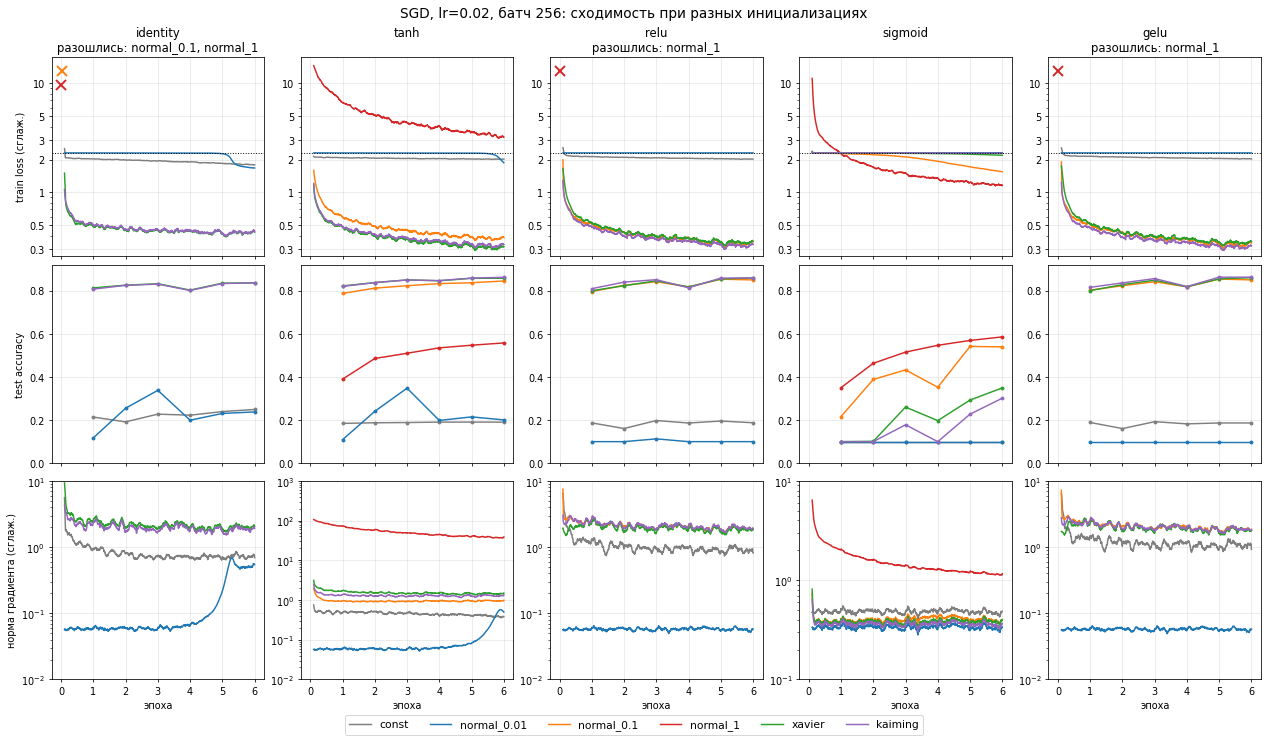

In [16]:
def smooth_curve(values, window=25):
    v = np.asarray(values, dtype=float)
    x = np.arange(1, len(v) + 1) / ITERS_PER_EPOCH
    if len(v) < window:
        return x, v
    return x[window - 1:], np.convolve(v, np.ones(window) / window, mode="valid")


LOSS_TICKS = [0.1, 0.2, 0.3, 0.5, 1, 2, 3, 5, 10, 20, 30, 50, 100]


def plot_training_curves(hists):
    fig, axes = plt.subplots(3, len(ACT_FNS), figsize=(18, 10.5), dpi=70, sharex=True, layout="constrained")
    diverged, loss_vals = {}, []
    for c, act_name in enumerate(ACT_FNS):
        diverged[act_name], grad_vals = [], []
        for method in INIT_METHODS:
            h, color = hists[(act_name, method)], INIT_COLORS[method]
            x_l, l_sm = smooth_curve(h["iter_loss"])
            axes[0, c].plot(x_l, l_sm, color=color, label=method)
            if h["diverged_at"] is not None:
                diverged[act_name].append(method)
                continue
            loss_vals += l_sm.tolist()
            axes[1, c].plot(np.arange(1, len(h["test_acc"]) + 1), h["test_acc"], "o-", ms=3, color=color)
            x_g, g_sm = smooth_curve(h["iter_grad"])
            axes[2, c].plot(x_g, g_sm, color=color)
            grad_vals += g_sm.tolist()
        names = diverged[act_name]
        axes[0, c].set_title(act_name + ("\nразошлись: " + ", ".join(names) if names else "\n"), fontsize=12)
        axes[1, c].set_ylim(0, 0.92)
        axes[2, c].set_yscale("log")
        snap_log_ylim(axes[2, c], grad_vals)
        axes[2, c].set_xlabel("эпоха")
        for ax in axes[:, c]:
            ax.grid(alpha=0.3)
    # общая логарифмическая шкала лосса по всем панелям (по запускам, которые не разошлись)
    loss_lo, loss_hi = 0.9 * min(loss_vals), 1.2 * max(loss_vals)
    for c, act_name in enumerate(ACT_FNS):
        ax = axes[0, c]
        ax.set_yscale("log")
        ax.set_ylim(loss_lo, loss_hi)
        ax.set_yticks([t for t in LOSS_TICKS if loss_lo <= t <= loss_hi])
        ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%g"))
        ax.yaxis.set_minor_formatter(plt.NullFormatter())
        ax.axhline(math.log(10), color="black", ls=":", lw=1)
        for k, method in enumerate(diverged[act_name]):
            h = hists[(act_name, method)]
            ax.plot(h["diverged_at"][1] / ITERS_PER_EPOCH, loss_hi / 1.35 ** (k + 1), "x",
                    ms=10, mew=2, color=INIT_COLORS[method])
    axes[0, 0].set_ylabel("train loss (сглаж.)")
    axes[1, 0].set_ylabel("test accuracy")
    axes[2, 0].set_ylabel("норма градиента (сглаж.)")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=len(INIT_METHODS), fontsize=11)
    fig.suptitle(f"SGD, lr={SGD_LR}, батч {SGD_BATCH}: сходимость при разных инициализациях", fontsize=14)
    plt.show()


plot_training_curves(train_hist)

Итоговая точность на тесте после 6 эпох (серым - разошедшиеся запуски) и таблица с точностью на тесте после каждой эпохи и средним train loss на первой и последней эпохе (для разошедшихся запусков - итерация, на которой появился `nan`/`inf`).

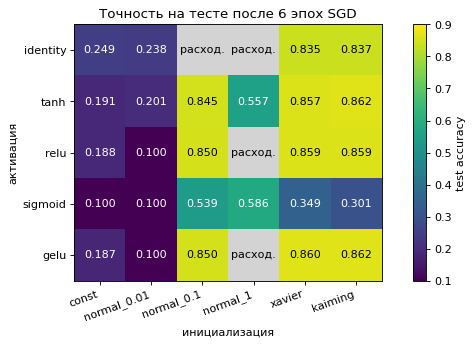

acc эп. 1  acc эп. 2  acc эп. 3  acc эп. 4  acc эп. 5  acc эп. 6  train loss эп. 1  train loss (посл.)     nan/inf
активация инициализация                                                                                                                    
identity  const              0.214      0.192      0.228      0.223      0.239      0.249             2.093               1.813            
          normal_0.01        0.117      0.255      0.338      0.199      0.231      0.238             2.302               1.840            
          normal_0.1           NaN        NaN        NaN        NaN        NaN        NaN               NaN                 NaN  итерация 9
          normal_1             NaN        NaN        NaN        NaN        NaN        NaN               NaN                 NaN  итерация 3
          xavier             0.813      0.826      0.832      0.802      0.835      0.835             0.640               0.422            
          kaiming            0.807      0.825      0.830      0.801      0.833      0.837             0.615               0.427            
tanh      const              0.185      0.188      0.189      0.191      0.191      0.191             2.097               2.019            
          normal_0.01        0.109      0.241      0.348      0.198      0.215      0.201             2.302               2.187            
          normal_0.1         0.787      0.812      0.823      0.833      0.837      0.845             0.829               0.379            
          normal_1           0.390      0.485      0.510      0.535      0.547      0.557             9.433               3.361            
          xavier             0.822      0.837      0.850      0.846      0.857      0.857             0.625               0.310            
          kaiming            0.819      0.837      0.849      0.847      0.858      0.862             0.641               0.327            
relu      const              0.187      0.161      0.198      0.186      0.196      0.188             2.190               2.025            
          normal_0.01        0.100      0.100      0.113      0.100      0.100      0.100             2.303               2.303            
          normal_0.1         0.796      0.824      0.841      0.817      0.853      0.850             0.742               0.339            
          normal_1             NaN        NaN        NaN        NaN        NaN        NaN               NaN                 NaN  итерация 3
          xavier             0.799      0.823      0.845      0.817      0.854      0.859             0.753               0.347            
          kaiming            0.809      0.840      0.851      0.813      0.858      0.859             0.646               0.323            
sigmoid   const              0.100      0.100      0.100      0.100      0.100      0.100             2.304               2.304            
          normal_0.01        0.100      0.100      0.100      0.100      0.100      0.100             2.303               2.303            
          normal_0.1         0.216      0.388      0.433      0.352      0.541      0.539             2.291               1.619            
          normal_1           0.350      0.463      0.515      0.547      0.569      0.586             3.831               1.186            
          xavier             0.100      0.102      0.260      0.198      0.293      0.349             2.308               2.215            
          kaiming            0.100      0.100      0.178      0.100      0.227      0.301             2.306               2.285            
gelu      const              0.189      0.161      0.193      0.182      0.187      0.187             2.198               2.036            
          normal_0.01        0.100      0.100      0.100      0.100      0.100      0.100             2.303               2.303            
          normal_0.1         0.802      0.823      0.841      0.817      0.854      0.850             0.7

In [17]:
def plot_final_accuracy(hists):
    act_list = list(ACT_FNS)
    final_acc = np.full((len(act_list), len(INIT_METHODS)), np.nan)
    for i, act_name in enumerate(act_list):
        for j, method in enumerate(INIT_METHODS):
            h = hists[(act_name, method)]
            if h["diverged_at"] is None:
                final_acc[i, j] = h["test_acc"][-1]
    acc_cmap = plt.get_cmap("viridis").copy()
    acc_cmap.set_bad("lightgray")
    fig, ax = plt.subplots(figsize=(9, 4.2), dpi=80, layout="constrained")
    img = ax.imshow(np.ma.masked_invalid(final_acc), cmap=acc_cmap, vmin=0.1, vmax=0.9)
    for i in range(len(act_list)):
        for j in range(len(INIT_METHODS)):
            acc = final_acc[i, j]
            label = "расход." if np.isnan(acc) else f"{acc:.3f}"
            ax.text(j, i, label, ha="center", va="center", color="black" if np.isnan(acc) or acc > 0.6 else "white")
    ax.set_xticks(range(len(INIT_METHODS)), INIT_METHODS, rotation=20, ha="right")
    ax.set_yticks(range(len(act_list)), act_list)
    ax.set_xlabel("инициализация")
    ax.set_ylabel("активация")
    ax.set_title(f"Точность на тесте после {SGD_EPOCHS} эпох SGD")
    fig.colorbar(img, ax=ax, label="test accuracy")
    plt.show()


def make_train_table(hists):
    table_rows = []
    for (act_name, method), h in hists.items():
        res = {"активация": act_name, "инициализация": method}
        for e in range(SGD_EPOCHS):
            res[f"acc эп. {e + 1}"] = h["test_acc"][e] if e < len(h["test_acc"]) else np.nan
        res["train loss эп. 1"] = h["train_loss"][0] if h["train_loss"] else np.nan
        res["train loss (посл.)"] = h["train_loss"][-1] if h["train_loss"] else np.nan
        res["nan/inf"] = f"итерация {h['diverged_at'][1]}" if h["diverged_at"] else ""
        table_rows.append(res)
    return pd.DataFrame(table_rows).set_index(["активация", "инициализация"])


plot_final_accuracy(train_hist)
train_results = make_train_table(train_hist)
with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
    display(train_results)

### Sigmoid: Xavier с gain 4

Как обещал в п. 1.3, проверим отдельно вариант Xavier с gain 4 для sigmoid: он должен скомпенсировать множитель $\sigma'(0) = 1/4$, но не смещение 0.5. Сначала те же статистики на батче из 1024 картинок, что и в п. 1.4 (по слоям: std выхода по примерам, т.е. полезная часть сигнала, и RMS градиента весов), потом обучение с теми же настройками SGD. Для сравнения рядом обычный `xavier` (gain 1) и лучший для sigmoid в основном эксперименте `normal_1`.

,"std по примерам, xavier","std по примерам, xavier, gain 4","std по примерам, normal_1","rms grad W, xavier","rms grad W, xavier, gain 4","rms grad W, normal_1"
слой 1: 784->512,0.178,0.335,0.416,5.3e-05,0.00259,0.00271
слой 2: 512->256,0.0474,0.201,0.328,0.000226,0.0082,0.00577
слой 3: 256->256,0.0112,0.116,0.255,0.000994,0.0171,0.0116
слой 4: 256->128,0.00295,0.0659,0.189,0.00509,0.0367,0.0248
слой 5: 128->10,0.00387,0.409,2.64,0.0587,0.177,0.182


,acc эп. 1,acc эп. 2,acc эп. 3,acc эп. 4,acc эп. 5,acc эп. 6,loss на старте,train loss эп. 1,train loss (посл.)
xavier,0.1,0.102,0.26,0.198,0.293,0.349,2.68,2.31,2.22
"xavier, gain 4",0.716,0.755,0.777,0.788,0.796,0.806,10.4,1.45,0.549
normal_1,0.35,0.463,0.515,0.547,0.569,0.586,23.3,3.83,1.19


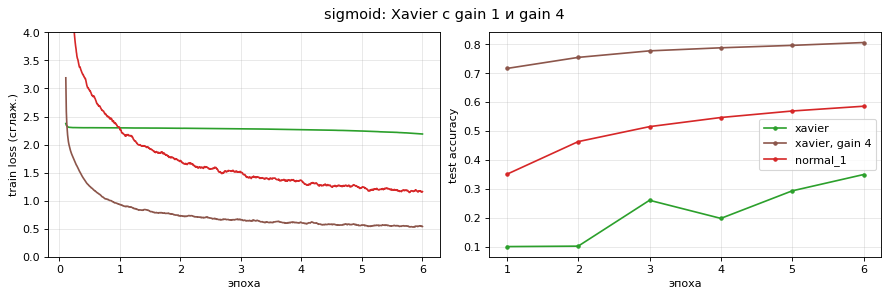

In [18]:
def run_sigmoid_gain_check():
    # sigmoid с xavier (gain 1 и 4) и normal_1: статистики на старте и обучение
    variants = {"xavier": ("xavier", None), "xavier, gain 4": ("xavier", 4.0), "normal_1": ("normal_1", None)}
    stats, hists = {}, {}
    for label, (method, gain) in variants.items():
        stats[label] = collect_layer_stats(make_init_model("sigmoid", method, seed=0, gain=gain), x_probe, y_probe)
        if gain is None:
            hists[label] = train_hist[("sigmoid", method)]  # эти уже обучены выше
        else:
            _, hists[label] = train_with_init("sigmoid", method, gain=gain)
    return stats, hists


def show_sigmoid_gain_check(stats, hists):
    layer_table = pd.DataFrame(
        {**{f"std по примерам, {lb}": [s["sample_std"] for s in st["acts"]] for lb, st in stats.items()},
         **{f"rms grad W, {lb}": [s["rms"] for s in st["grads"]] for lb, st in stats.items()}},
        index=LAYER_LABELS,
    )
    acc_table = pd.DataFrame({lb: h["test_acc"] for lb, h in hists.items()},
                             index=[f"acc эп. {e + 1}" for e in range(SGD_EPOCHS)]).T
    acc_table["loss на старте"] = [st["loss"] for st in stats.values()]
    acc_table["train loss эп. 1"] = [h["train_loss"][0] for h in hists.values()]
    acc_table["train loss (посл.)"] = [h["train_loss"][-1] for h in hists.values()]
    with pd.option_context("display.float_format", "{:.3g}".format, "display.width", 250, "display.max_columns", 20):
        display(layer_table)
        display(acc_table)

    colors = {"xavier": INIT_COLORS["xavier"], "xavier, gain 4": "tab:brown", "normal_1": INIT_COLORS["normal_1"]}
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), dpi=80, layout="constrained")
    for label, h in hists.items():
        axes[0].plot(*smooth_curve(h["iter_loss"]), color=colors[label], label=label)
        axes[1].plot(np.arange(1, len(h["test_acc"]) + 1), h["test_acc"], "o-", ms=3, color=colors[label], label=label)
    axes[0].set_ylim(0, 4)
    axes[0].set_ylabel("train loss (сглаж.)")
    axes[1].set_ylabel("test accuracy")
    for ax in axes:
        ax.set_xlabel("эпоха")
        ax.grid(alpha=0.3)
    axes[1].legend()
    fig.suptitle("sigmoid: Xavier с gain 1 и gain 4", fontsize=13)
    plt.show()


sig_stats, sig_hist = run_sigmoid_gain_check()
show_sigmoid_gain_check(sig_stats, sig_hist)

Gain 4 действительно сильно помогает. Полезный сигнал по слоям все еще затухает, но примерно в 1.7 раза на слой (std по примерам 0.34, 0.20, 0.12, 0.066), а не в 4 раза, как при gain 1 (0.18, 0.047, 0.011, 0.003). Полностью компенсировать $\sigma'(0)=1/4$ не получается, потому что из-за смещения 0.5 предактивации сдвинуты от нуля туда, где производная sigmoid уже меньше 1/4. Градиент весов первого слоя меньше, чем у последнего, в 70 раз (0.0026 против 0.18), как у `normal_1`, а не в 1000 раз, как при gain 1. Начальный лосс большой (10.4): логиты получают большую добавку от смещения 0.5, одинаковую для всех картинок, но она уходит уже в первые сотни итераций. В итоге точность 0.716 после первой эпохи и 0.806 после шестой (train loss 0.549), тогда как у лучшего из основных вариантов `normal_1` 0.586, а у обычного `xavier` 0.349. До tanh, ReLU и GELU с хорошей инициализацией (0.857-0.862) sigmoid все равно не дотягивает: смещение среднего никуда не делось, и сигнал продолжает затухать с глубиной.

### Симметрия при константной инициализации

При `const` все нейроны слоя считают одно и то же и получают одинаковые градиенты, значит они должны остаться одинаковыми и после обучения. Проверим на весах первого слоя: для каждого входного пикселя считаем std весов по 512 нейронам и берем максимум по пикселям. Для сравнения - те же числа для `xavier` и `kaiming`.

,const,xavier,kaiming
identity,0,0.0445,0.0406
tanh,0,0.0741,0.0675
relu,0,0.0446,0.0573
sigmoid,0,0.0442,0.0402
gelu,0,0.0446,0.0572


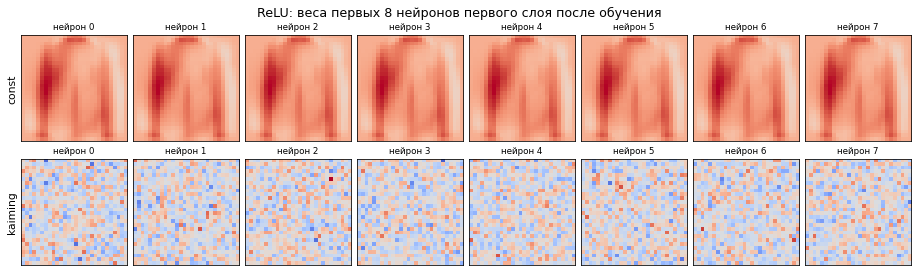

In [19]:
def show_symmetry(hists, w1_weights):
    methods = ["const", "xavier", "kaiming"]
    w1_spread = pd.DataFrame(
        {m: [hists[(a, m)]["w1_neuron_spread"] for a in ACT_FNS] for m in methods},
        index=list(ACT_FNS),
    )
    with pd.option_context("display.float_format", "{:.3g}".format):
        display(w1_spread)

    # веса первых 8 нейронов первого слоя ReLU-сети после обучения
    fig, axes = plt.subplots(2, 8, figsize=(13, 3.8), dpi=70, layout="constrained")
    for r, method in enumerate(["const", "kaiming"]):
        w = w1_weights[method][:8]
        w_max = w.abs().max().item()
        for k in range(8):
            axes[r, k].imshow(w[k].view(28, 28), cmap="coolwarm", vmin=-w_max, vmax=w_max)
            axes[r, k].set_xticks([])
            axes[r, k].set_yticks([])
            axes[r, k].set_title(f"нейрон {k}", fontsize=9)
        axes[r, 0].set_ylabel(method, fontsize=11)
    fig.suptitle("ReLU: веса первых 8 нейронов первого слоя после обучения", fontsize=13)
    plt.show()


show_symmetry(train_hist, w1_examples)

### Выводы по обучению

- Быстрее и лучше всего учатся те пары, которые в п. 1.4 оказались стабильными: tanh + `kaiming`/`xavier` (0.862 / 0.857 на тесте после 6 эпох), ReLU + `kaiming`/`xavier` (0.859 / 0.859), GELU + `kaiming`/`xavier` (0.862 / 0.860). Все они дают около 80% уже после первой эпохи (0.80-0.82). Линейная сеть (identity) с `kaiming`/`xavier` упирается примерно в 0.84 - это потолок линейного классификатора, глубина ей ничего не дает.
- Про точность цифр. Каждая пара обучалась один раз с одним сидом, а точность на тесте и так скачет от эпохи к эпохе на 0.01-0.03, поэтому разницу меньше примерно 0.005 (например, между tanh, ReLU и GELU с хорошей инициализацией) я бы не считал значимой. Провал на 4-й эпохе виден сразу у identity, ReLU и GELU (у ReLU + `kaiming` 0.851 -> 0.813 -> 0.858), у tanh он слабее. Порядок батчей во всех запусках одинаковый, а lr постоянный, так что это особенность конкретной последовательности батчей, а не инициализации. Уверенно можно говорить о больших эффектах: скорость на первой эпохе, плато, расхождение, `const` и sigmoid.
- Для ReLU и GELU разница между `kaiming` и `xavier` к 6-й эпохе почти исчезла, но на старте `kaiming` быстрее: средний train loss на первой эпохе 0.646 против 0.753 у ReLU и 0.625 против 0.767 у GELU. Сеть у нас неглубокая, и потеря ~25% std на слой при `xavier` еще не критична.
- `normal_0.1` для tanh, ReLU и GELU учится почти так же хорошо (0.845-0.850), хотя первая эпоха хуже. А для identity тот же `normal_0.1` расходится: в линейной сети ничто не ограничивает рост сигнала (std логитов ~15), градиенты большие, и при lr = 0.02 лосс за несколько шагов вырастает до ~1e12, а на 9-й итерации становится `nan`.
- `normal_1`: для identity, ReLU и GELU расхождение почти сразу. На старте градиенты весов порядка 1e2-1e4, после первого же шага SGD лосс подскакивает с ~1e6 до ~1e16, а на 3-й итерации получается `nan`/`inf`. Для tanh и sigmoid расхождения нет (активации ограничены), но tanh учится плохо: точность 0.56 и train loss 3.36 на последней эпохе (на графике это красная линия заметно выше пунктира $\ln 10$, на первой эпохе лосс в среднем 9.4). Нейроны насыщены, а логиты огромные, так что сеть очень уверенно ошибается.
- `normal_0.01`: классическое плато. Сигнал и градиенты почти нулевые, и лосс стоит на $\ln 10 \approx 2.303$. Линейная сеть выбирается с плато только к концу 5-й эпохи (лосс резко падает, норма градиента растет), tanh - в конце 6-й, а ReLU и GELU за 6 эпох так и не сдвинулись (точность 0.10, т.е. для всех картинок один и тот же ответ).
- `const`: точность 0.19-0.25 и почти не растет, потому что все нейроны в слое одинаковые и сеть фактически имеет ширину 1. С sigmoid не учится совсем (0.10).
- sigmoid учится хуже всех. Среди шести основных инициализаций лучшие результаты у `normal_1` (0.586) и `normal_0.1` (0.539), а "правильные" `xavier` и `kaiming` дают только 0.349 и 0.301 при train loss 2.2-2.3. Это согласуется с анализом выше: при `normal_1` полезный сигнал по слоям затухает меньше всего, а при `xavier`/`kaiming` градиент первого слоя примерно в 1000 раз меньше, чем последнего, и при lr = 0.02 первые слои почти не учатся. Xavier с gain 4 (см. выше) заметно лучше всех шести: 0.806 после 6 эпох, но и это ниже, чем у tanh, ReLU и GELU.
- После обучения с `const` веса первого слоя у всех нейронов совпадают: std по нейронам ровно 0 для всех активаций, а у `xavier` и `kaiming` он порядка 0.04-0.07. На картинке видно, что все 8 нейронов ReLU-сети с `const` выучили один и тот же шаблон, а у `kaiming` все нейроны разные.

In [20]:
# дальше данные в этом задании не нужны, освобождаем память (задание 3 загружает их заново)
del x_train, y_train, x_test, y_test, x_probe, y_probe, w1_examples

## Выводы по заданию 1

- Масштаб весов нужно выбирать под размер слоя и функцию активации. Фиксированный std не подходит: 0.01 дает затухание сигнала и градиентов и плато в начале обучения, 1 - взрыв (identity, ReLU и GELU уже на 3-й итерации получают `nan`/`inf`) или насыщение (tanh, sigmoid), а 0.1 для tanh, ReLU и GELU еще терпимо, но линейную сеть уже разгоняет до расхождения.
- Стабильные активации и градиенты дают: для identity - LeCun ($1/n_{in}$) или Xavier ($2/(n_{in}+n_{out})$), для tanh - Xavier с gain 5/3 (или LeCun с тем же gain), для ReLU и GELU - Kaiming ($2/n_{in}$). С ними std выходов скрытых слоев держится примерно в пределах 0.65-1.5 (около 1 у identity + `kaiming`, 1.1-1.45 у identity + `xavier`, 0.66-0.77 у tanh, около 0.8 у ReLU, 0.70-0.86 у GELU), градиенты по выходам слоев и по весам меняются от слоя к слою в разы, а не на порядки (RMS градиента весов от 5e-3 до 0.16), и SGD сходится быстрее всего: около 80% на тесте после первой эпохи и 0.84-0.86 после шести.
- Константная инициализация не работает ни с какой активацией: симметрия между нейронами не ломается, и после обучения все нейроны первого слоя остаются одинаковыми.
- Бонус. GELU ведет себя почти как ReLU и с Kaiming дает 0.862, как tanh + `kaiming`; разница с ReLU (0.859) в пределах шума от одного сида. Sigmoid с шестью основными инициализациями учится плохо: из-за смещенного среднего и $\sigma' \le 1/4$ полезный сигнал и градиенты к первым слоям затухают на порядки (Glorot и Bengio в своей статье тоже отмечают проблемы sigmoid с насыщением). Xavier с gain 4, который компенсирует $\sigma'(0) = 1/4$, поднимает ее с 0.35 до 0.806, но смещение 0.5 он не убирает, и sigmoid все равно отстает от tanh, ReLU и GELU. Поэтому в скрытых слоях обычно используют их.
- При хорошей инициализации разница между tanh, ReLU и GELU после 6 эпох небольшая (0.857-0.862) и меньше, чем разброс от эпохи к эпохе, а линейная сеть отстает (0.837), потому что глубина без нелинейности ничего не добавляет.

## Источники

- X. Glorot, Y. Bengio. Understanding the difficulty of training deep feedforward neural networks, AISTATS 2010. https://proceedings.mlr.press/v9/glorot10a.html
- K. He, X. Zhang, S. Ren, J. Sun. Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification, ICCV 2015. https://arxiv.org/abs/1502.01852
- Y. LeCun, L. Bottou, G. Orr, K.-R. Müller. Efficient BackProp, 1998. http://yann.lecun.com/exdb/publis/pdf/lecun-98b.pdf
- P. Lippe. UvA Deep Learning Tutorials, Tutorial 4: Optimization and Initialization (оттуда `BaseNetwork` и идея анализа). https://uvadlc-notebooks.readthedocs.io/en/latest/tutorial_notebooks/tutorial4/Optimization_and_Initialization.html
- D. Hendrycks, K. Gimpel. Gaussian Error Linear Units (GELUs), 2016. https://arxiv.org/abs/1606.08415
- Документация PyTorch, `torch.nn.init` (формулы и gain для разных активаций). https://pytorch.org/docs/stable/nn.init.html